# Phase 3: Features + classification (sama, patient 0)

Regions to classify = sama's **own candidates**: the dark spots inside her predicted liver (watershed, Phase 2), i.e. exactly what the app hands to the SVM.
- **healthy** = every candidate spot with no tumour pixels (mostly vessels): exactly what the app classifies
- **tumour** = candidate spots at least 50% inside the ground-truth tumour **plus the ground-truth tumour blobs** they miss (hybrid: patient 0's tumours are too small for the candidates to isolate, see the counts printed below)

Features: shape + GLCM (0/45/90/135 degrees) + first-order HU + **Hu moments** (sama's own set). Classifier: **SVM (RBF kernel)**.

In [1]:
import os, glob
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import skew, kurtosis
from skimage.measure import regionprops, label
from skimage.feature import graycomatrix, graycoprops
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score
import joblib

NAME = "sama"
SLICES = f"../data/slices/{NAME}"            # raw CT (HU) + ground-truth masks
ENH = "../phase1/outputs_sama/enhanced"           # Phase 1 output
LIVER = "../phase2/outputs_sama/watershed"        # Phase 2 output (your best method)
OUT = "outputs_sama"
FIGS = "../report/figures/sama"
os.makedirs(OUT, exist_ok=True)

slice_ids = sorted(os.path.basename(f).replace("_enh.png", "") for f in glob.glob(f"{ENH}/*_enh.png"))
print(len(slice_ids), "slices")

def load(sid):
    ct = np.load(f"{SLICES}/{sid}_ct.npy")                              # raw HU (for first-order stats)
    enh = cv2.imread(f"{ENH}/{sid}_enh.png", 0)                         # enhanced 0-255 (for texture)
    liver = cv2.imread(f"{LIVER}/{sid}_liver_pred.png", 0) > 0          # YOUR predicted liver
    tumour = cv2.imread(f"{SLICES}/{sid}_tumour.png", 0) > 0            # ground-truth tumour
    return ct, enh, liver, tumour

16 slices


In [2]:
MIN_AREA = 10          # ignore regions smaller than 10 pixels (too small to measure)

def candidate_spots(enh, liver):
    """Dark spots inside the liver = things that could be tumour (tumours are darker than liver)."""
    inner = cv2.erode(liver.astype(np.uint8), np.ones((9, 9), np.uint8)) > 0   # stay away from the edge
    if not inner.any():
        return np.zeros_like(liver)
    dark = (enh < np.median(enh[inner]) - 25) & inner
    return cv2.morphologyEx(dark.astype(np.uint8), cv2.MORPH_OPEN, np.ones((3, 3), np.uint8)) > 0

pure_counts = {"tumour": 0, "healthy": 0}      # what the candidates alone give (printed below)
rois, skipped, added_gt = [], 0, 0             # (slice id, region mask, label)  label: 1 = tumour, 0 = healthy
for sid in slice_ids:
    ct, enh, liver, tumour = load(sid)
    cand_tumours = []
    for r in regionprops(label(candidate_spots(enh, liver))):
        if r.area < MIN_AREA:
            continue
        m = np.zeros(tumour.shape, bool); m[tuple(r.coords.T)] = True
        inside = tumour[m].mean()                     # share of the spot that is real tumour
        if inside >= 0.5:
            rois.append((sid, m, 1)); cand_tumours.append(m); pure_counts["tumour"] += 1
        elif inside == 0:
            rois.append((sid, m, 0)); pure_counts["healthy"] += 1
        else:
            skipped += 1
    # hybrid step: add each ground-truth tumour blob that no tumour candidate already covers (>= 50% of the blob)
    for r in regionprops(label(tumour)):
        if r.area < MIN_AREA:
            continue
        m = np.zeros(tumour.shape, bool); m[tuple(r.coords.T)] = True
        if not any((m & c).sum() >= 0.5 * m.sum() for c in cand_tumours):
            rois.append((sid, m, 1)); added_gt += 1

labels = np.array([y for _, _, y in rois])
print(f"Candidates alone: {pure_counts['tumour']} tumour vs {pure_counts['healthy']} healthy ({skipped} mixed spots skipped).")
print(f"NOTE: the tumour class is partly GROUND TRUTH. Patient 0's tumours are too small to isolate with the dark-spot")
print(f"candidates (only {pure_counts['tumour']} tumour vs {pure_counts['healthy']} healthy), so {added_gt} ground-truth tumour blobs were added.")
print(f"Healthy regions are all real candidates, exactly what the app classifies. The classifier uses balanced class weights.")
print(len(rois), "regions:", (labels == 1).sum(), "tumour,", (labels == 0).sum(), "healthy")

Candidates alone: 8 tumour vs 142 healthy (5 mixed spots skipped).
NOTE: the tumour class is partly GROUND TRUTH. Patient 0's tumours are too small to isolate with the dark-spot
candidates (only 8 tumour vs 142 healthy), so 18 ground-truth tumour blobs were added.
Healthy regions are all real candidates, exactly what the app classifies. The classifier uses balanced class weights.
168 regions: 26 tumour, 142 healthy


In [3]:
ANGLES = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]           # 0, 45, 90, 135 degrees
ANGLE_NAMES = ["0", "45", "90", "135"]

def shape_features(mask):
    r = regionprops(mask.astype(np.uint8))[0]
    area, perim = r.area, max(r.perimeter, 1e-6)
    return {"area": area,
            "perimeter_area_ratio": perim / area,
            "circularity": 4 * np.pi * area / perim ** 2,      # 1 = perfect circle
            "compactness": perim ** 2 / area,
            "eccentricity": r.eccentricity,                      # 0 = circle, 1 = line
            "solidity": r.solidity}                              # area / convex hull area

def glcm_features(enh, mask, levels=32, per_angle=False):
    """GLCM texture inside the region only (pixels outside the region are ignored)."""
    r = regionprops(mask.astype(np.uint8))[0]
    r0, c0, r1, c1 = r.bbox
    patch = enh[r0:r1, c0:c1].astype(int)
    m = mask[r0:r1, c0:c1]
    q = np.where(m, 1 + patch * (levels - 1) // 255, 0).astype(np.uint8)   # 1..levels inside, 0 outside
    P = graycomatrix(q, distances=[1], angles=ANGLES, levels=levels + 1)
    P = P[1:, 1:, :, :].astype(float)                                      # drop pairs touching "outside"
    P = P / np.maximum(P.sum(axis=(0, 1), keepdims=True), 1e-12)
    feats = {}
    for prop in ["energy", "contrast", "homogeneity", "correlation"]:
        vals = np.nan_to_num(graycoprops(P, prop)[0])                     # one value per angle
        feats.update({f"glcm_{prop}_{a}": v for a, v in zip(ANGLE_NAMES, vals)} if per_angle
                     else {f"glcm_{prop}": vals.mean()})
    ent = [-(P[:, :, 0, k][P[:, :, 0, k] > 0] * np.log2(P[:, :, 0, k][P[:, :, 0, k] > 0])).sum() for k in range(4)]
    feats.update({f"glcm_entropy_{a}": v for a, v in zip(ANGLE_NAMES, ent)} if per_angle
                 else {"glcm_entropy": np.mean(ent)})
    return feats

def first_order_features(ct, mask):
    hu = ct[mask].astype(float)
    return {"mean_HU": hu.mean(), "variance_HU": hu.var(),
            "skewness": skew(hu) if hu.std() > 0 else 0.0,
            "kurtosis": kurtosis(hu) if hu.std() > 0 else 0.0}

# GLCM table at the 4 angles for one tumour (for the report)
sid, m, _ = next(r for r in rois if r[2] == 1)
ct, enh, _, _ = load(sid)
glcm_table = pd.Series(glcm_features(enh, m, per_angle=True))
print(f"GLCM at 4 angles, tumour region in {sid}:")
print(pd.DataFrame({a: glcm_table[[k for k in glcm_table.index if k.endswith("_" + a)]].values
                    for a in ANGLE_NAMES},
                   index=["energy", "contrast", "homogeneity", "correlation", "entropy"]).round(3))
pd.DataFrame({a: glcm_table[[k for k in glcm_table.index if k.endswith("_" + a)]].values for a in ANGLE_NAMES},
             index=["energy", "contrast", "homogeneity", "correlation", "entropy"]).round(3).to_csv(f"{FIGS}/{NAME}_glcm_table.csv")

GLCM at 4 angles, tumour region in p0_s46:
                 0     45     90    135
energy       0.432  0.427  0.403  0.375
contrast     0.368  0.333  0.513  1.135
homogeneity  0.816  0.833  0.744  0.627
correlation  0.918  0.897  0.876  0.762
entropy      2.813  2.830  2.891  3.072


In [4]:
def hu_moment_features(mask):
    """sama's own feature set: the 7 Hu moment invariants of the region's shape. They do not change when the
    region is moved, scaled or rotated. Log-scaled (-sign x log10|h|) because the raw values span many orders of magnitude."""
    hu = cv2.HuMoments(cv2.moments(mask.astype(np.uint8), binaryImage=True)).ravel()
    return {f"hu_{i + 1}": -np.sign(h) * np.log10(abs(h)) if h != 0 else 0.0 for i, h in enumerate(hu)}

cache = {}
rows = []
for sid, m, y in rois:
    if sid not in cache:
        cache[sid] = load(sid)
    ct, enh, _, _ = cache[sid]
    rows.append({"slice": sid, "label": y,
                 **shape_features(m), **glcm_features(enh, m), **first_order_features(ct, m), **hu_moment_features(m)})
features = pd.DataFrame(rows)
features.to_csv(f"{OUT}/phase3_features.csv", index=False)
print(features.groupby("label").mean(numeric_only=True).T.round(3).rename(columns={0: "healthy", 1: "tumour"}))

label                 healthy   tumour
area                  173.183   91.962
perimeter_area_ratio    0.517    0.498
circularity             0.814    0.919
compactness            21.535   14.456
eccentricity            0.779    0.706
solidity                0.867    0.909
glcm_energy             0.562    0.491
glcm_contrast           0.466    0.385
glcm_homogeneity        0.821    0.809
glcm_correlation        0.562    0.666
glcm_entropy            2.098    2.425
mean_HU                94.992   91.368
variance_HU           270.529  202.303
skewness               -0.136   -0.007
kurtosis               -0.205   -0.069
hu_1                    0.645    0.716
hu_2                    1.958    2.410
hu_3                    2.615    3.394
hu_4                    3.592    4.827
hu_5                    1.543    0.390
hu_6                    0.706   -0.793
hu_7                    1.262   -0.371


In [5]:
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, GridSearchCV, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score
import joblib

X = features.drop(columns=["slice", "label"]).values
y = features["label"].values

# ---- groups: every region from the same slice stays on the same side of the split ----
# Neighbouring slices show the same tumour, so a random split of regions would put near-copies in train AND test.
# Consecutive slices are joined into blocks of 3 (or 2) only if that still leaves >= 5 training groups for 5-fold CV.
slice_no = features["slice"].str.extract(r"_s(\d+)")[0].astype(int)
position = slice_no.map({s: i for i, s in enumerate(sorted(slice_no.unique()))}).values   # 0, 1, 2, ... along the scan
def grouped_split(groups):
    """70/30 split by group. Groups differ in size, so try 50 seeds and keep the one whose test part is closest
    to 30% of the REGIONS (only sizes are looked at, never the scores). Needs >= 5 train groups + both classes in test."""
    best_split, best_gap = None, 1.0
    for seed in range(50):
        tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=seed).split(X, y, groups))
        if len(np.unique(groups[tr])) >= 5 and len(np.unique(y[te])) == 2 and abs(len(te) / len(y) - 0.3) < best_gap:
            best_split, best_gap = (tr, te), abs(len(te) / len(y) - 0.3)
    return best_split

for BLOCK in (3, 2, 1):
    groups = position // BLOCK
    split = grouped_split(groups)
    if split is not None:
        break
idx_train, idx_test = split
X_train, X_test, y_train, y_test = X[idx_train], X[idx_test], y[idx_train], y[idx_test]
print(f"block = {BLOCK} slice(s) per group | train: {len(np.unique(groups[idx_train]))} groups, {len(idx_train)} regions"
      f" | test: {len(np.unique(groups[idx_test]))} groups, {len(idx_test)} regions"
      f" ({len(idx_test) / len(y):.0%} of all regions)")

from sklearn.svm import SVC
# SVM: draws the widest possible boundary between the tumour and healthy points;
# class_weight='balanced' makes a missed tumour cost as much as all the extra healthy spots together
# 5-fold grouped cross-validation on the 70% TRAIN part only picks the C; the 30% test part stays untouched
cv5 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
search = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel="rbf", gamma="scale", class_weight="balanced")),
                      {"svc__C": [0.1, 1, 10, 100]}, cv=cv5, scoring="f1")
search.fit(X_train, y_train, groups=groups[idx_train])
best = search.best_params_["svc__C"]
model = search.best_estimator_                     # already refitted on the whole 70% train part
y_pred = model.predict(X_test)

cv = cross_validate(model, X_train, y_train, groups=groups[idx_train], cv=cv5, scoring=["accuracy", "f1"])
print(f"tuned C = {best}  (tried [0.1, 1, 10, 100])")
print(f"5-fold grouped CV on train: accuracy {cv['test_accuracy'].mean():.3f} +/- {cv['test_accuracy'].std():.3f}"
      f"  folds: {np.round(cv['test_accuracy'], 3)}")
print(f"                            F1       {cv['test_f1'].mean():.3f} +/- {cv['test_f1'].std():.3f}"
      f"  folds: {np.round(cv['test_f1'], 3)}")
cv_summary = {"tuned C": best, "group block (slices)": BLOCK,
              "CV accuracy mean": cv["test_accuracy"].mean(), "CV accuracy std": cv["test_accuracy"].std(),
              "CV F1 mean": cv["test_f1"].mean(), "CV F1 std": cv["test_f1"].std()}

block = 2 slice(s) per group | train: 5 groups, 118 regions | test: 3 groups, 50 regions (30% of all regions)
tuned C = 1  (tried [0.1, 1, 10, 100])
5-fold grouped CV on train: accuracy 0.826 +/- 0.149  folds: [0.875 0.882 1.    0.552 0.821]
                            F1       0.599 +/- 0.253  folds: [0.5   0.714 1.    0.235 0.545]


Test set: 50 regions (7 tumour, 43 healthy)
  accuracy               0.760
  sensitivity (recall)   0.857
  specificity            0.744
  F1                     0.500


95% bootstrap CI (test groups resampled):
  accuracy               [0.583, 0.864]
  sensitivity (recall)   [0.500, 1.000]
  specificity            [0.500, 0.900]
  F1                     [0.400, 0.600]


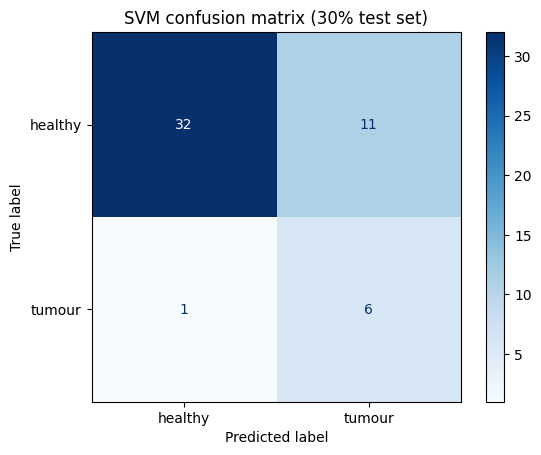

In [6]:
tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
metrics = {"accuracy": accuracy_score(y_test, y_pred),
           "sensitivity (recall)": tp / (tp + fn) if tp + fn else 0,   # tumours correctly found
           "specificity": tn / (tn + fp) if tn + fp else 0,            # healthy correctly cleared
           "F1": f1_score(y_test, y_pred, zero_division=0)}
print(f"Test set: {len(y_test)} regions ({(y_test == 1).sum()} tumour, {(y_test == 0).sum()} healthy)")
for k, v in metrics.items():
    print(f"  {k:22s} {v:.3f}")
# ---- 95% confidence intervals: bootstrap over the test GROUPS (slices), 2000 resamples ----
def scores(t, p):
    tn, fp, fn, tp = confusion_matrix(t, p, labels=[0, 1]).ravel()
    return [accuracy_score(t, p), tp / (tp + fn) if tp + fn else np.nan, tn / (tn + fp) if tn + fp else np.nan,
            f1_score(t, p, zero_division=0)]
boot_rng = np.random.default_rng(0)
test_groups = groups[idx_test]
boot = []
for _ in range(2000):
    pick = np.concatenate([np.where(test_groups == g)[0] for g in boot_rng.choice(np.unique(test_groups), len(np.unique(test_groups)))])
    boot.append(scores(y_test[pick], y_pred[pick]))
lo, hi = np.nanpercentile(boot, 2.5, axis=0), np.nanpercentile(boot, 97.5, axis=0)
ci = {}
print("95% bootstrap CI (test groups resampled):")
for k, a, b in zip(metrics, lo, hi):
    ci[f"{k} CI low"], ci[f"{k} CI high"] = a, b
    print(f"  {k:22s} [{a:.3f}, {b:.3f}]")
pd.DataFrame([{**metrics, **cv_summary, **ci}]).to_csv(f"{OUT}/phase3_metrics.csv", index=False)

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=[0, 1]),
                       display_labels=["healthy", "tumour"]).plot(cmap="Blues")
plt.title("SVM confusion matrix (30% test set)")
plt.savefig(f"{FIGS}/{NAME}_p3_confusion_matrix.png", dpi=120, bbox_inches="tight"); plt.show()

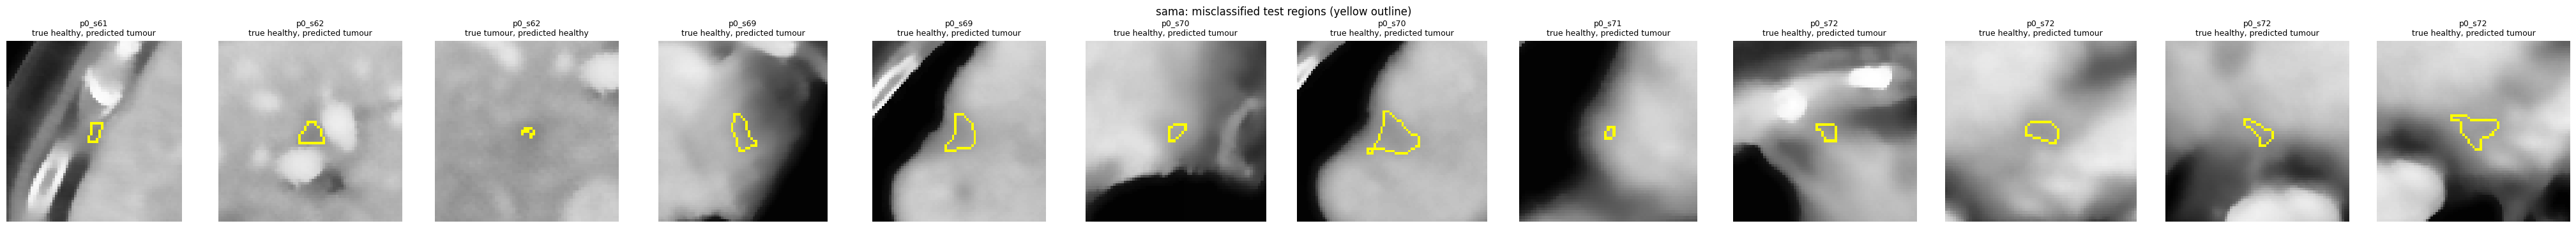

# Phase 3 failed cases: sama

Test set: 50 regions, **12 misclassified**.

| Slice | True | Predicted | Area (px) | Mean HU | Most unlike its true class (feature value, z-score vs training regions of that class) |
|---|---|---|---|---|---|
| p0_s61 | healthy | tumour | 36 | 49 | mean_HU 48.6 (z -2.0), skewness 0.676 (z +2.0), glcm_homogeneity 0.656 (z -1.7) |
| p0_s62 | healthy | tumour | 68 | 89 | hu_2 4.58 (z +3.3), eccentricity 0.24 (z -3.2), hu_6 -8.57 (z -1.8) |
| p0_s62 | tumour | healthy | 12 | 99 | skewness 0.955 (z +2.1), kurtosis 1.18 (z +2.1), circularity 1.29 (z +2.0) |
| p0_s69 | healthy | tumour | 103 | 47 | mean_HU 46.7 (z -2.1), glcm_correlation 0.897 (z +1.1), hu_7 -7.99 (z -1.1) |
| p0_s69 | healthy | tumour | 135 | 82 | hu_5 -7.03 (z -1.2), hu_6 -4.94 (z -1.1), hu_7 -7.44 (z -1.0) |
| p0_s70 | healthy | tumour | 37 | 63 | mean_HU 62.9 (z -1.5), hu_5 -8.63 (z -1.4), hu_6 -5.81 (z -1.3) |
| p0_s70 | healthy | tumour | 236 | 88 | eccentricity 0.474 (z -1.8), hu_2 3.21 (

In [7]:
# ---- failed cases: the test regions the classifier got wrong ----
FAILED = f"../report/failed_cases/{NAME}"
os.makedirs(FAILED, exist_ok=True)
wrong = idx_test[y_pred != y_test]
names = {0: "healthy", 1: "tumour"}
lines = [f"# Phase 3 failed cases: {NAME}", "",
         f"Test set: {len(y_test)} regions, **{len(wrong)} misclassified**.", "",
         "| Slice | True | Predicted | Area (px) | Mean HU | Most unlike its true class (feature value, z-score vs training regions of that class) |", "|---|---|---|---|---|---|"]
feat_cols = list(features.columns[2:])
train_feats = features.iloc[idx_train]
for i in wrong:
    sid, m, true = rois[i]
    row = features.iloc[i]
    # measured reason: the 3 features where this region is most unlike the TRAINING regions of its true class (|z-score|)
    own_class = train_feats[train_feats.label == true][feat_cols]
    z = ((row[feat_cols] - own_class.mean()) / (own_class.std() + 1e-9)).astype(float)
    top = z.abs().sort_values(ascending=False).index[:3]
    why = ", ".join(f"{f} {row[f]:.3g} (z {z[f]:+.1f})" for f in top)
    lines.append(f"| {sid} | {names[true]} | {names[1 - true]} | {int(row['area'])} | {row['mean_HU']:.0f} | {why} |")
if len(wrong):
    fig, axes = plt.subplots(1, len(wrong), figsize=(3.4 * len(wrong), 3.6), squeeze=False)
    for a, i in zip(axes[0], wrong):
        sid, m, true = rois[i]
        rgb = cv2.cvtColor(load(sid)[1], cv2.COLOR_GRAY2RGB)
        contours, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(rgb, contours, -1, (255, 255, 0), 1)
        ys, xs = np.where(m)
        y0, y1, x0, x1 = max(ys.min() - 30, 0), ys.max() + 30, max(xs.min() - 30, 0), xs.max() + 30
        a.imshow(rgb[y0:y1, x0:x1]); a.axis("off")
        a.set_title(f"{sid}\ntrue {names[true]}, predicted {names[1 - true]}", fontsize=9)
    plt.suptitle(f"{NAME}: misclassified test regions (yellow outline)")
    plt.tight_layout(); plt.savefig(f"{FAILED}/{NAME}_p3_misclassified.png", dpi=120, bbox_inches="tight"); plt.show()
else:
    lines.append("| - | - | - | - | - | no mistakes in this test split |")
open(f"{FAILED}/{NAME}_phase3_failed_cases.md", "w").write("\n".join(lines))
print("\n".join(lines))

In [8]:
model.fit(X, y)                                  # final model trained on all regions
joblib.dump({"model": model, "feature_names": list(features.columns[2:])}, f"{OUT}/svm_model.joblib")
print("saved model to", f"{OUT}/svm_model.joblib")

saved model to outputs_sama/svm_model.joblib


**Feature analysis.** 1) Box plots of every feature, healthy vs tumour. 2) Mann-Whitney U test per feature (does the feature differ between the classes? no normal distribution needed). 3) Ablation: the same tuned classifier trained on one feature group at a time, scored with the same grouped split (grouped 5-fold CV on the 70% + the untouched 30%).

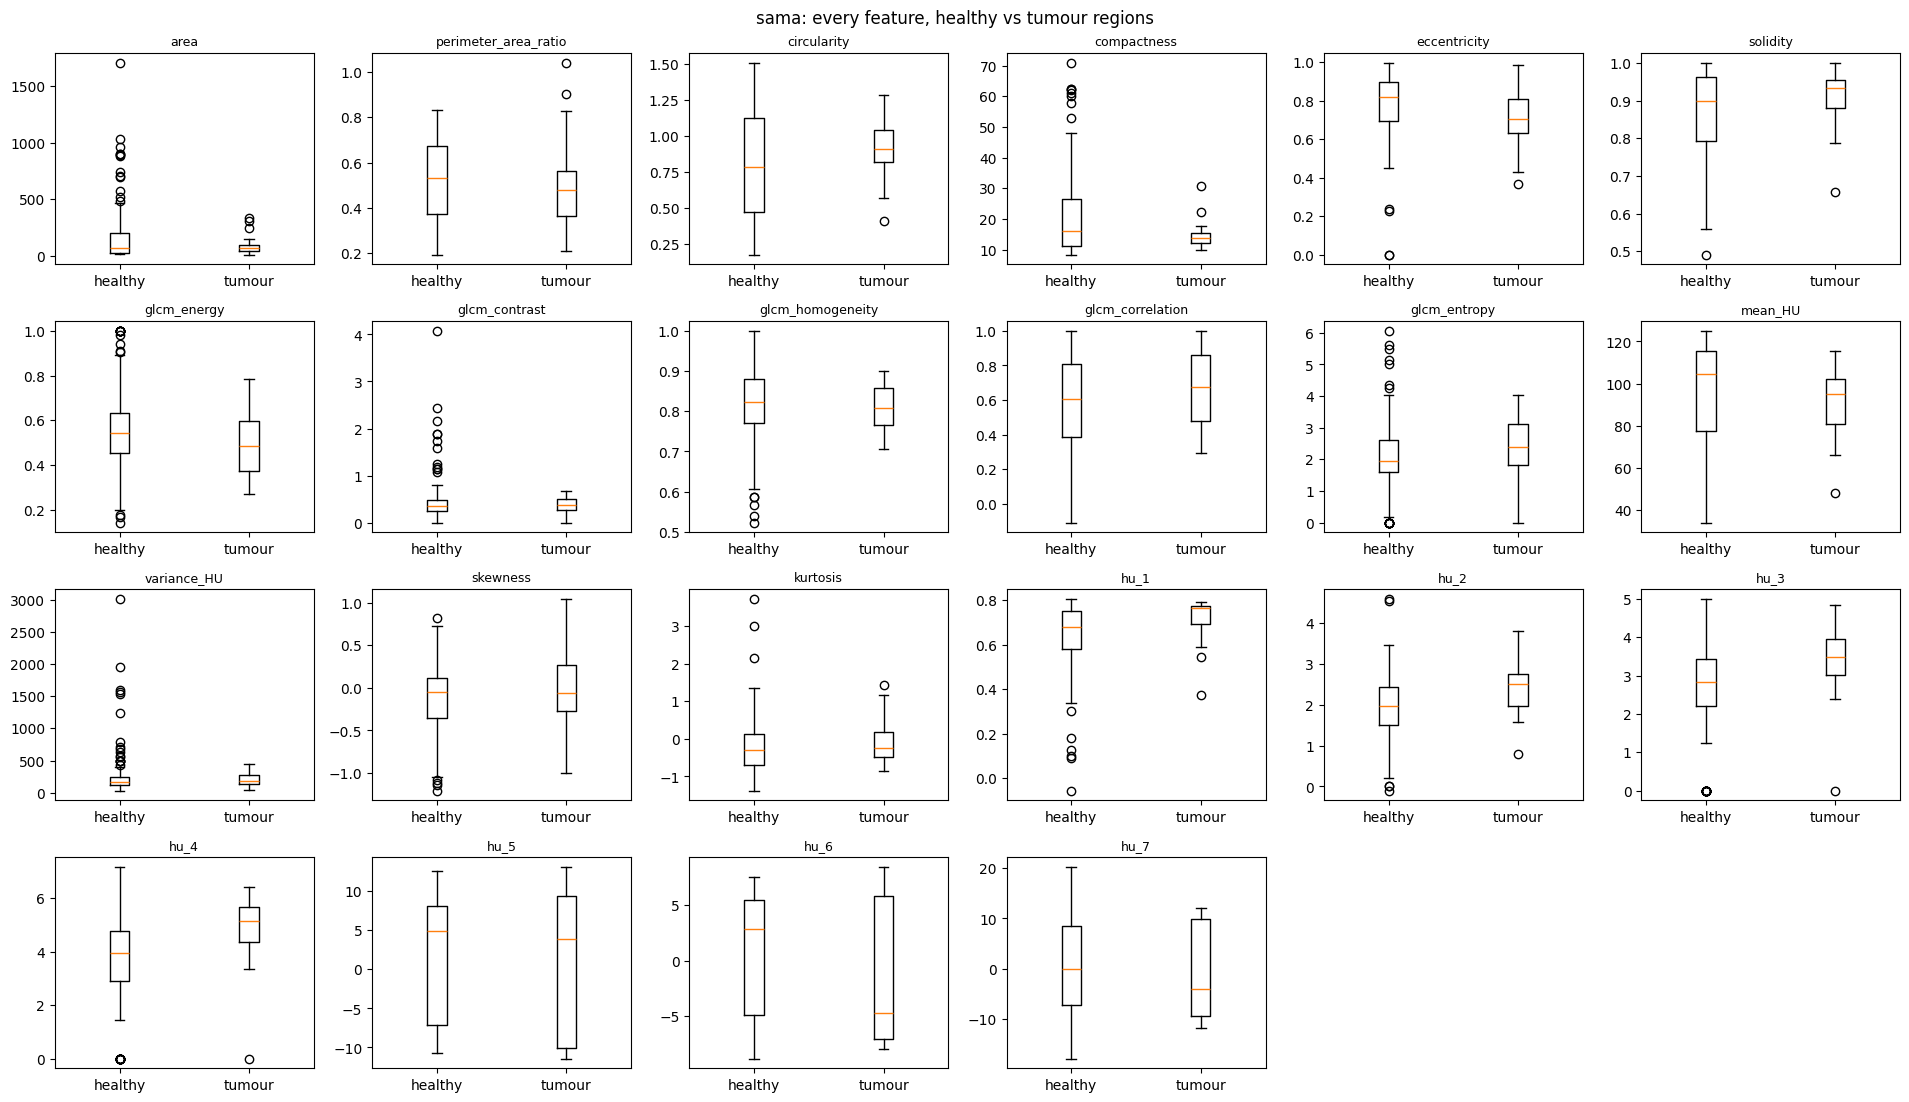

Mann-Whitney U, healthy vs tumour (smallest p first):
             feature  median healthy  median tumour  p-value  significant (p < 0.05)
                hu_4          3.9481         5.1337   0.0000                    True
                hu_3          2.8425         3.4839   0.0007                    True
                hu_2          1.9709         2.4997   0.0026                    True
        eccentricity          0.8185         0.7030   0.0037                    True
                hu_1          0.6809         0.7631   0.0112                    True
        glcm_entropy          1.9510         2.3952   0.0629                   False
         glcm_energy          0.5437         0.4851   0.0739                   False
             mean_HU        104.6749        94.8741   0.0969                   False
         circularity          0.7848         0.9079   0.1719                   False
         compactness         16.0118        13.8421   0.1719                   False
    glcm_co

In [9]:
from scipy.stats import mannwhitneyu
from sklearn.base import clone

feature_names = list(features.columns[2:])
healthy, tumorous = features[features.label == 0], features[features.label == 1]

# 1) box plots, healthy vs tumour
cols = 6
rows_n = int(np.ceil(len(feature_names) / cols))
fig, axes = plt.subplots(rows_n, cols, figsize=(3.2 * cols, 2.8 * rows_n))
for a, f in zip(axes.ravel(), feature_names):
    a.boxplot([healthy[f], tumorous[f]]); a.set_xticks([1, 2], ["healthy", "tumour"]); a.set_title(f, fontsize=9)
for a in axes.ravel()[len(feature_names):]:
    a.axis("off")
plt.suptitle(f"{NAME}: every feature, healthy vs tumour regions"); plt.tight_layout()
plt.savefig(f"{FIGS}/{NAME}_p3_feature_boxplots.png", dpi=110); plt.show()

# 2) Mann-Whitney U test per feature
tests = pd.DataFrame([{"feature": f, "median healthy": healthy[f].median(), "median tumour": tumorous[f].median(),
                       "p-value": mannwhitneyu(healthy[f], tumorous[f]).pvalue} for f in feature_names]).sort_values("p-value")
tests["significant (p < 0.05)"] = tests["p-value"] < 0.05
tests.to_csv(f"{OUT}/phase3_feature_tests.csv", index=False)
print("Mann-Whitney U, healthy vs tumour (smallest p first):")
print(tests.round(4).to_string(index=False))

# 3) ablation: one feature group at a time, same tuned classifier, same grouped split
SHAPE = ["area", "perimeter_area_ratio", "circularity", "compactness", "eccentricity", "solidity"]
FIRST_ORDER = ["mean_HU", "variance_HU", "skewness", "kurtosis"]
GROUPS = {"all features": feature_names, "shape only": SHAPE,
          "GLCM only": [f for f in feature_names if f.startswith("glcm_")], "first-order only": FIRST_ORDER,
          "Hu moments only": [f for f in feature_names if f.startswith("hu_")]}
ablation = []
for group_name, cols_used in GROUPS.items():
    idx = [feature_names.index(c) for c in cols_used]
    clf = clone(search.best_estimator_)
    cv_f1 = cross_validate(clf, X_train[:, idx], y_train, groups=groups[idx_train], cv=cv5, scoring="f1")["test_score"]
    pred = clf.fit(X_train[:, idx], y_train).predict(X_test[:, idx])
    ablation.append({"features": group_name, "n": len(idx), "CV F1 mean": cv_f1.mean(), "CV F1 std": cv_f1.std(),
                     "test accuracy": accuracy_score(y_test, pred), "test F1": f1_score(y_test, pred, zero_division=0)})
ablation = pd.DataFrame(ablation)
ablation.to_csv(f"{OUT}/phase3_ablation.csv", index=False)
print("\nAblation (same tuned classifier, same grouped split):")
print(ablation.round(3).to_string(index=False))